# 06c — User segments (K-Means + PCA)

Per-user features from **train only** (as of T1 = 2022-07-01). Users first seen after T1 have no segment; later phases give them `segment_id = -1` ("new user").

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, "../src")
from shoprank.features.user_features import user_features

T1 = pd.Timestamp("2022-07-01")
PROC, FIG = Path("../data/processed"), Path("../reports/figures")
train = pd.read_parquet(PROC / "train.parquet")
items = pd.read_parquet(PROC / "items.parquet")

feats = user_features(train, items, as_of=T1)
feats.describe().round(2)

,n_purchases,days_since_last,avg_price_paid,avg_rating_given,verified_share,n_stores
count,22324.00,22324.00,22324.00,22324.00,22324.00,22324.00
mean,6.70,537.00,57.08,4.33,0.90,5.32
std,5.06,420.75,48.96,0.78,0.24,3.06
min,1.00,0.00,3.49,1.00,0.00,1.00
25%,5.00,170.00,27.83,4.00,1.00,4.00
50%,6.00,446.00,41.65,4.58,1.00,5.00
75%,7.00,857.00,69.28,5.00,1.00,6.00
max,251.00,1641.00,999.00,5.00,1.00,56.00


## Scale, then cluster for k = 2…10

Counts, days and price are long-tailed (max 251 purchases, $999), so they are `log1p`-transformed before `StandardScaler`; otherwise K-Means spends clusters on a handful of extreme users.

        inertia  silhouette
2   111859.1566      0.2067
3    96747.5187      0.1799
4    84427.9697      0.2021
5    74605.9729      0.1952
6    66926.2606      0.2074
7    60137.4561      0.2175
8    57236.1078      0.2169
9    54716.5499      0.2029
10   52451.4154      0.1858


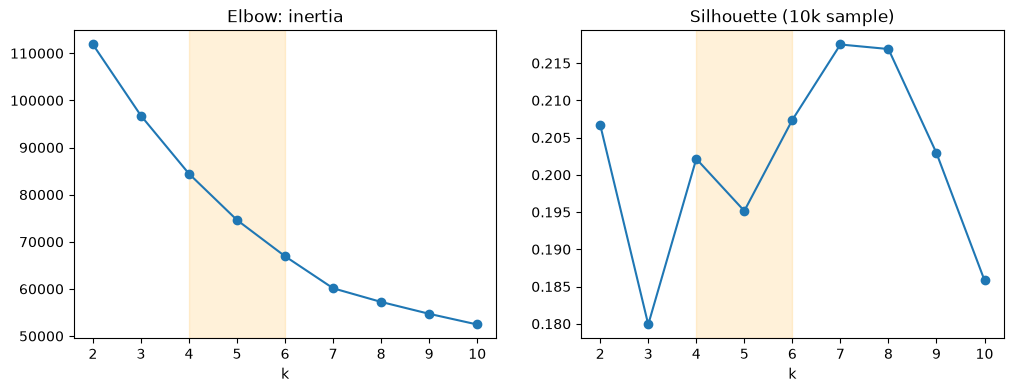

In [2]:
LOG_COLS = ["n_purchases", "days_since_last", "avg_price_paid", "n_stores"]
model_input = feats.copy()
model_input[LOG_COLS] = np.log1p(model_input[LOG_COLS])
scaler = StandardScaler().fit(model_input)
Z = scaler.transform(model_input)

ks = range(2, 11)
fits = {k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(Z) for k in ks}
curve = pd.DataFrame({
    "inertia": [fits[k].inertia_ for k in ks],
    "silhouette": [silhouette_score(Z, fits[k].labels_, sample_size=10_000, random_state=42) for k in ks],
}, index=ks)
print(curve.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
curve["inertia"].plot(ax=axes[0], marker="o", title="Elbow: inertia")
curve["silhouette"].plot(ax=axes[1], marker="o", title="Silhouette (10k sample)")
for ax in axes:
    ax.axvspan(4, 6, color="orange", alpha=0.15)
    ax.set_xlabel("k")
plt.savefig(FIG / "segments_k.png", dpi=120, bbox_inches="tight")
plt.show()

## Pick k

The elbow has no sharp bend and silhouette stays around 0.2 for every k — the users form overlapping groups, not crisp ones. Within the usual 4–6 range the best silhouette wins.

In [3]:
K = int(curve.loc[4:6, "silhouette"].idxmax())
kmeans = fits[K]
feats["segment_id"] = kmeans.labels_
profile = feats.groupby("segment_id").mean().assign(users=feats["segment_id"].value_counts().sort_index())
print(f"k = {K}")
profile.round(2)

k = 6


,n_purchases,days_since_last,avg_price_paid,avg_rating_given,verified_share,n_stores,users
segment_id,,,,,,,
0,2.40,412.71,39.27,4.54,0.95,1.88,1849
1,5.86,634.60,107.64,4.60,0.96,4.50,4935
2,8.13,375.52,61.15,4.16,0.15,6.48,1515
3,5.34,361.28,60.50,2.90,0.90,4.62,2925
4,5.81,661.11,30.27,4.62,0.97,4.89,8061
5,13.63,374.52,51.62,4.46,0.94,9.95,3039


## Name each segment from its averages

Assigned by rules on the profile (not by cluster number, which can change if the data changes): the most extreme cluster on each trait takes that name, and the last two split on price.

In [4]:
def name_segments(profile):
    left = profile.copy()
    names = {}
    rules = [
        ("Unverified reviewers", "verified_share", "min"),
        ("Critical raters", "avg_rating_given", "min"),
        ("Frequent multi-store buyers", "n_purchases", "max"),
        ("Light buyers", "n_purchases", "min"),
    ]
    for name, col, how in rules:
        if len(left) <= 2:
            break
        seg = left[col].idxmin() if how == "min" else left[col].idxmax()
        names[seg] = name
        left = left.drop(seg)
    by_price = left["avg_price_paid"].sort_values()
    lapsed = ", lapsed" if (left["days_since_last"] > profile["days_since_last"].median()).all() else ""
    names[by_price.index[0]] = "Budget buyers" + lapsed
    names[by_price.index[-1]] = "Premium buyers" + lapsed
    return names

names = name_segments(profile)
assert len(set(names.values())) == K
profile.insert(0, "segment_name", profile.index.map(names))
feats["segment_name"] = feats["segment_id"].map(names)
profile.round(2)

,segment_name,n_purchases,days_since_last,avg_price_paid,avg_rating_given,verified_share,n_stores,users
segment_id,,,,,,,,
0,Light buyers,2.40,412.71,39.27,4.54,0.95,1.88,1849
1,"Premium buyers, lapsed",5.86,634.60,107.64,4.60,0.96,4.50,4935
2,Unverified reviewers,8.13,375.52,61.15,4.16,0.15,6.48,1515
3,Critical raters,5.34,361.28,60.50,2.90,0.90,4.62,2925
4,"Budget buyers, lapsed",5.81,661.11,30.27,4.62,0.97,4.89,8061
5,Frequent multi-store buyers,13.63,374.52,51.62,4.46,0.94,9.95,3039


## PCA to 2D

explained variance: PC1 31.7%, PC2 21.4%
     n_purchases  days_since_last  avg_price_paid  avg_rating_given  \
PC1         0.69            -0.12            0.11              0.03   
PC2         0.13             0.49           -0.22              0.60   

     verified_share  n_stores  
PC1           -0.16      0.69  
PC2            0.57      0.09  


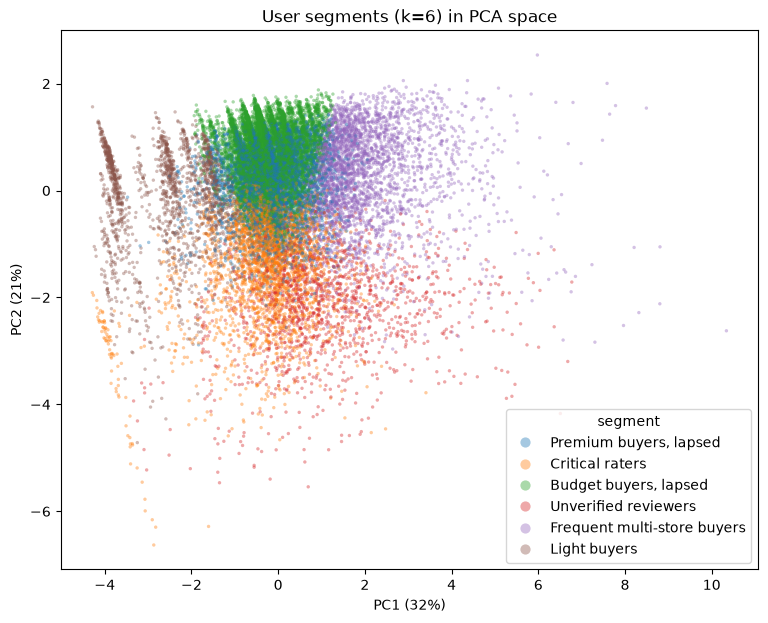

In [5]:
pca = PCA(n_components=2, random_state=42).fit(Z)
P = pca.transform(Z)
print(f"explained variance: PC1 {pca.explained_variance_ratio_[0]:.1%}, PC2 {pca.explained_variance_ratio_[1]:.1%}")
print(pd.DataFrame(pca.components_, columns=feats.columns[:6], index=["PC1", "PC2"]).round(2))

fig, ax = plt.subplots(figsize=(9, 7))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=feats["segment_name"], s=6, alpha=0.4, linewidth=0, ax=ax)
ax.set(title=f"User segments (k={K}) in PCA space",
       xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%})", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%})")
ax.legend(markerscale=3, title="segment")
plt.savefig(FIG / "segments_pca.png", dpi=120, bbox_inches="tight")
plt.show()

## Save `segment_id` per user

In [6]:
out = feats.reset_index()
out.to_parquet(PROC / "user_segments.parquet", index=False)
print(f"saved {len(out):,} users")
out["segment_name"].value_counts()

saved 22,324 users


segment_name
Budget buyers, lapsed          8061
Premium buyers, lapsed         4935
Frequent multi-store buyers    3039
Critical raters                2925
Light buyers                   1849
Unverified reviewers           1515
Name: count, dtype: int64